- Before learning Backpropogation we, we will see how do DL models are trained and used for prediction. 
    - In this lesson we will cover binary classification problem. 
    - In next lesson we will cover multi-class classification problem.
    - Then the third lesson will be about regression problem.

In [1]:
import numpy as np
import pandas as pd

In [2]:
!pip install kagglehub


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rjmanoj/credit-card-customer-churn-prediction")

print("Path to dataset files:", path)

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: C:\Users\Kaushik Mandal\.cache\kagglehub\datasets\rjmanoj\credit-card-customer-churn-prediction\versions\1


In [4]:
import os
import glob

csv_files = glob.glob(os.path.join(path, "*.csv"))
print(csv_files)

df = pd.read_csv(csv_files[0])

['C:\\Users\\Kaushik Mandal\\.cache\\kagglehub\\datasets\\rjmanoj\\credit-card-customer-churn-prediction\\versions\\1\\Churn_Modelling.csv']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [5]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df['Exited'].value_counts()

Exited
0    7963
1    2037
Name: count, dtype: int64

- Its a imbalance dataset. We have 80% of data with class 0 and 20% of data with class 1. But we will not get into fixing imbalance dataset in this lesson. We just want to see the implementation 

In [11]:
df.drop(columns = ['RowNumber','CustomerId','Surname'],inplace=True)

In [12]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [13]:
df['Geography'].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [14]:
df['Gender'].value_counts()

Gender
Male      5457
Female    4543
Name: count, dtype: int64

- One hot encode the Geographt and Gender columns. We will use pandas get_dummies function for that.

In [15]:
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True) 

In [16]:
df.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,1,False,False,False
1,608,41,1,83807.86,1,0,1,112542.58,0,False,True,False
2,502,42,8,159660.80,3,1,0,113931.57,1,False,False,False
3,699,39,1,0.00,2,0,0,93826.63,0,False,False,False
4,850,43,2,125510.82,1,1,1,79084.10,0,False,True,False


In [17]:
X = df.drop(columns=['Exited'])
y = df['Exited'].values

from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=0)

- In the dataset you can see some columns have very small values and some columns have very large values. We will scale the data using StandardScaler from sklearn.This is important for NN to converge faster.

In [18]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_trf = scaler.fit_transform(X_train)
X_test_trf = scaler.transform(X_test)

In [22]:
type(X_train_trf), type(X_train)

(numpy.ndarray, pandas.core.frame.DataFrame)

In [28]:
X_train[0:2:1]

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
7389,667,34,5,0.00,2,1,0,163830.64,False,True,False
9275,427,42,1,75681.52,1,1,1,57098.00,True,False,True


In [ ]:
# X_train_trf[0:2:1] uses Python slicing in the form [start:stop:step]
# start = 0  -> begin from row index 0
# stop  = 2  -> go up to (but not including) row index 2
# step  = 1  -> take every row
# So this selects rows 0 and 1 from the scaled training data.

pd.DataFrame(X_train_trf[0:2:1], columns=X_train.columns)

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,0.169582,-0.464608,0.006661,-1.215717,0.809503,0.642595,-1.032270,1.106432,-0.569844,1.743090,-1.091687
1,-2.304559,0.301026,-1.377440,-0.006312,-0.921591,0.642595,0.968738,-0.748664,1.754865,-0.573694,0.916013


- See the values are scaled and now we can train our model on this data.

In [19]:
!pip install tensorflow

  Using cached markdown_it_py-4.0.0-py3-none-any.whl.metadata (7.3 kB)
  Using cached mdurl-0.1.2-py3-none-any.whl.metadata (1.6 kB)
   ---------------------------------------- 0.0/350.9 MB ? eta -:--:--
    --------------------------------------- 5.8/350.9 MB 29.3 MB/s eta 0:00:12
   - -------------------------------------- 11.5/350.9 MB 27.7 MB/s eta 0:00:13
   - -------------------------------------- 17.0/350.9 MB 27.5 MB/s eta 0:00:13
   -- ------------------------------------- 22.5/350.9 MB 26.9 MB/s eta 0:00:13
   --- ------------------------------------ 26.7/350.9 MB 26.1 MB/s eta 0:00:13
   --- ------------------------------------ 32.2/350.9 MB 26.2 MB/s eta 0:00:13
   ---- ----------------------------------- 37.2/350.9 MB 25.7 MB/s eta 0:00:13
   ---- ----------------------------------- 42.7/350.9 MB 25.9 MB/s eta 0:00:12
   ----- ---------------------------------- 48.0/350.9 MB 25.9 MB/s eta 0:00:12
   ------ --------------------------------- 53.7/350.9 MB 26.1 MB/s eta 0:00:


[notice] A new release of pip is available: 25.2 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [20]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential 
from tensorflow.keras.layers import Dense

- In keras we can make 2 types of model 
    - Sequential API
    - Non-sequential API (Functional API)

- We will use Sequential API/model for this lesson.

In [29]:
model = Sequential()

model.add(Dense(3,activation='sigmoid',input_dim=11)) # hidden layer with 3 neurons and sigmoid activation function. input_dim is the number of features in the input data.
model.add(Dense(1,activation='sigmoid')) # output layer with 1 neuron and sigmoid activation function. 

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


- We made this NN in the above code:

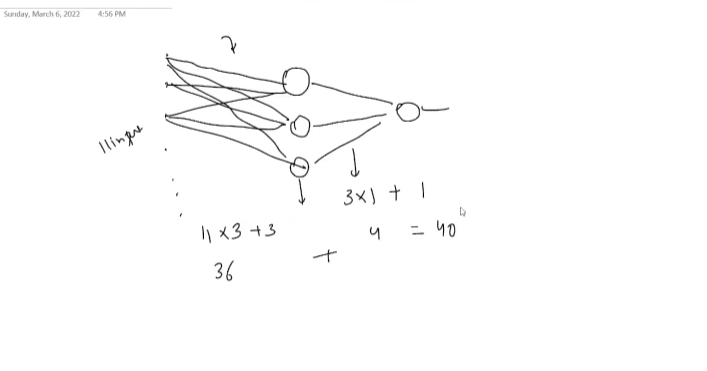

- So, our NN while training will learn 40 weights and biases (learnable parameters).

In [30]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 3)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │             4 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40 (160.00 B)

 Trainable params: 40 (160.00 B)

 Non-trainable params: 0 (0.00 B)

In [31]:
# Model compilation: we have to specify the optimizer, loss function and metrics to evaluate the model performance during training.
model.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [54]:
history = model.fit(X_train_trf,y_train,batch_size=50,epochs=100,verbose=1,validation_split=0.2)

Epoch 1/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7958 - loss: 0.5030 - val_accuracy: 0.7969 - val_loss: 0.4900
Epoch 2/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4821 - val_accuracy: 0.7969 - val_loss: 0.4755
Epoch 3/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4697 - val_accuracy: 0.7969 - val_loss: 0.4660
Epoch 4/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4606 - val_accuracy: 0.7969 - val_loss: 0.4586
Epoch 5/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4533 - val_accuracy: 0.7969 - val_loss: 0.4529
Epoch 6/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4473 - val_accuracy: 0.7969 - val_loss: 0.4482
Epoch 7/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7958 - loss: 0.4423 - val_accuracy: 0.7969 - val_loss: 0.4444
Epoch 8/100
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7956 - loss: 0.4382 - val_accu

In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

In [109]:
history.history

{'accuracy': [0.7901562452316284,
  0.7971875071525574,
  0.8021875023841858,
  0.811718761920929,
  0.8196874856948853,
  0.8243749737739563,
  0.8292187452316284,
  0.8326562643051147,
  0.8362500071525574,
  0.83984375,
  0.8446875214576721,
  0.8473437428474426,
  0.8512499928474426,
  0.8535937666893005,
  0.8590624928474426,
  0.8609374761581421,
  0.8590624928474426,
  0.8596875071525574,
  0.8595312237739563,
  0.8615624904632568,
  0.8615624904632568,
  0.8621875047683716,
  0.8623437285423279,
  0.8612499833106995,
  0.8620312213897705,
  0.8614062666893005,
  0.8628125190734863,
  0.8631250262260437,
  0.8617187738418579,
  0.8615624904632568,
  0.8620312213897705,
  0.8626562356948853,
  0.8618749976158142,
  0.8629687428474426,
  0.8607812523841858,
  0.8621875047683716,
  0.8631250262260437,
  0.8635937571525574,
  0.8610937595367432,
  0.8621875047683716,
  0.8634374737739563,
  0.8621875047683716,
  0.8621875047683716,
  0.8634374737739563,
  0.8629687428474426,
  0.864

In [55]:
model.layers[0].get_weights() # for the 1st hidden layer we have 33 weights (11 features * 3 neurons) and 3 biases (one for each neuron) = 36 learnable parameters

[array([[ 0.19876328, -0.22145407, -0.04225131],
        [-3.3276691 ,  2.4694896 ,  0.11367254],
        [ 0.53013283,  0.23492081,  0.07284303],
        [ 0.5021626 ,  0.38086236, -0.44836915],
        [-0.03361359, -0.188349  ,  0.17415138],
        [ 0.13747308,  0.13698861,  0.06609316],
        [-1.1086906 ,  0.69975597,  1.9474814 ],
        [ 0.14610513, -0.04933914, -0.22782245],
        [-0.20392755,  0.7224771 , -0.47968537],
        [-0.0733869 ,  0.24510692,  0.02677274],
        [-0.02460575, -0.45634556,  0.55456555]], dtype=float32),
 array([ 0.7977441 ,  0.23261954, -0.03782567], dtype=float32)]

In [56]:
model.layers[1].get_weights()

[array([[-1.5685413],
        [ 1.7290225],
        [-2.4884396]], dtype=float32),
 array([-0.3802618], dtype=float32)]

In [57]:
y_pred = model.predict(X_test_trf)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 870us/step


- The thing to notice here is that the output of the model is a probability value between 0 and 1. We need to convert this probability into a class label (0 or 1) based on a threshold (usually 0.5).

- Because we are using sigmoid activation function in the output layer, the output will be a probability value between 0 and 1. 

In [58]:
y_pred 

array([[0.2453354 ],
       [0.30417892],
       [0.19340003],
       ...,
       [0.13913831],
       [0.10206368],
       [0.1740797 ]], shape=(2000, 1), dtype=float32)

In [59]:
y_pred = y_pred.argmax(axis=-1)

In [60]:
type(y_pred)

numpy.ndarray

In [61]:
count0 = np.sum(y_pred == 0)
count1 = np.sum(y_pred == 1)

print(f"Number of samples predicted as class 0: {count0}")
print(f"Number of samples predicted as class 1: {count1}")

Number of samples predicted as class 0: 2000
Number of samples predicted as class 1: 0


In [62]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.7975

# Two graphs that you should always look at while training a NN are:
    - Training and validation accuracy graph
    - Training and validation loss graph

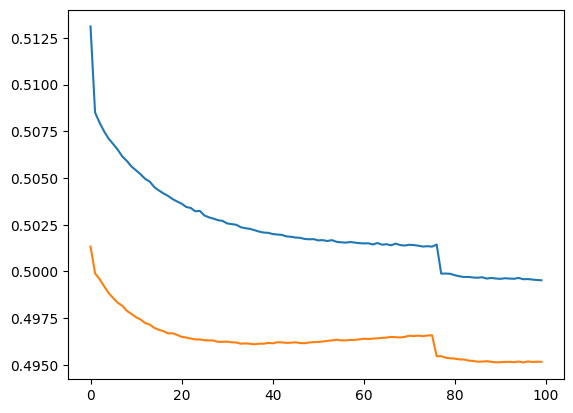

In [45]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

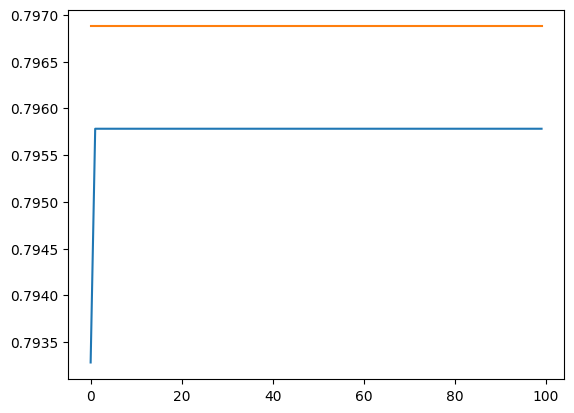

In [46]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

## Let's try changing the NN architecture

In [110]:
model1 = Sequential()

model1.add(Dense(11,activation='relu',input_dim=11)) # hidden layer with 11 neurons and relu activation function. input_dim is the number of features in the input data.
model1.add(Dense(11,activation='relu')) # hidden layer with 11 neurons and relu activation function.
model1.add(Dense(1,activation='sigmoid')) # output layer with 1 neuron and sigmoid activation function.

c:\Users\Kaushik Mandal\.virtualenvs\ClassicalML-_wR1sNSC\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [111]:
model1.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_14 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 11)             │           132 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            12 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 276 (1.08 KB)

 Trainable params: 276 (1.08 KB)

 Non-trainable params: 0 (0.00 B)

In [112]:
model1.compile(optimizer='Adam',loss='binary_crossentropy',metrics=['accuracy'])

In [113]:
history = model1.fit(X_train_trf,y_train,batch_size=50,epochs=200,verbose=1,validation_split=0.2)

Epoch 1/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.7531 - loss: 0.5332 - val_accuracy: 0.7969 - val_loss: 0.4796
Epoch 2/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7970 - loss: 0.4588 - val_accuracy: 0.7987 - val_loss: 0.4537
Epoch 3/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7998 - loss: 0.4388 - val_accuracy: 0.7987 - val_loss: 0.4411
Epoch 4/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8078 - loss: 0.4268 - val_accuracy: 0.8037 - val_loss: 0.4319
Epoch 5/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8152 - loss: 0.4174 - val_accuracy: 0.8131 - val_loss: 0.4231
Epoch 6/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8247 - loss: 0.4079 - val_accuracy: 0.8263 - val_loss: 0.4145
Epoch 7/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8325 - loss: 0.3980 - val_accuracy: 0.8275 - val_loss: 0.4053
Epoch 8/200
128/128 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8400 - loss: 0.3876 - val_accu

- ### The training accuracy should go up and the loss should go down.

- ### Also both the training and validation accuracy should go up in similar way and in our case we see trainig accuracy is 87% and validation accuracy is 85% which is good. It means there is some overfitting

In [114]:
model1.layers[0].get_weights() # for the 1st hidden layer we have 121 weights (11 features * 11 neurons) and 11 biases (one for each neuron) = 132 learnable parameters

[array([[ 0.16484275, -0.05104696, -0.12336597, -0.10843124,  0.05984255,
         -0.05942769,  0.03541095, -0.18531692, -0.12300089, -0.49362078,
         -0.10460612],
        [-0.32261178,  0.43399706,  0.41006076,  1.0875864 ,  0.18991564,
          0.53666574, -0.4266373 , -0.26465282,  0.9361309 , -0.7171865 ,
         -0.50486   ],
        [-0.43168002, -0.02145907, -0.0231509 , -0.02941906,  0.09743632,
          0.27172846,  0.01335078, -0.14882965, -0.17072575,  0.31866008,
          0.17130716],
        [-0.92865485, -1.0026842 , -0.27968863, -0.09786619, -0.4363279 ,
         -0.06917863, -0.727726  ,  0.35851085, -0.24067514,  0.23766197,
          0.4663945 ],
        [ 0.12963197, -0.76805395,  1.3826421 ,  0.09330872, -0.24215986,
          0.30601802, -0.385745  ,  0.12630899, -0.8871279 ,  0.65471804,
         -0.6179529 ],
        [ 0.13685215,  0.14273743,  0.05491129, -0.06643514, -0.02395765,
          0.01988246, -0.07465253,  0.05916841, -0.14024036,  0.0786924

In [115]:
y_pred = model1.predict(X_test_trf)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


In [116]:
y_pred = y_pred.argmax(axis=-1)

In [117]:
count0 = np.sum(y_pred == 0)
count1 = np.sum(y_pred == 1)

print(f"Number of samples predicted as class 0: {count0}")
print(f"Number of samples predicted as class 1: {count1}")

Number of samples predicted as class 0: 2000
Number of samples predicted as class 1: 0


In [118]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.7975

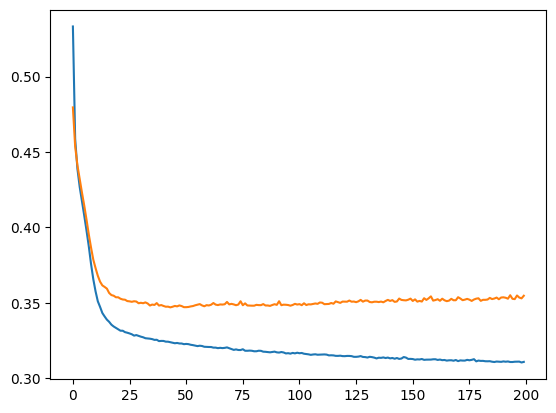

In [119]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

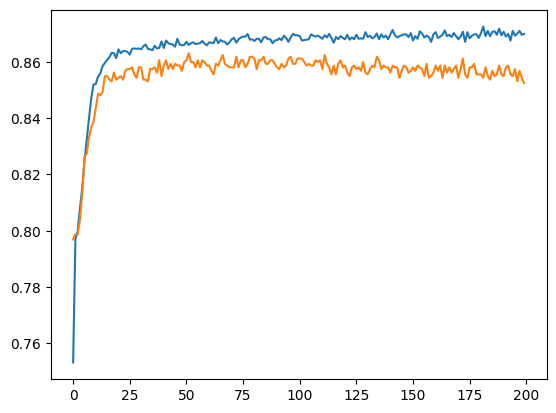

In [120]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])